# YouTube Content Moderation — biLSTM + Attention 

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_score, recall_score, f1_score
)

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, Bidirectional, LSTM,
    Dense, Dropout, SpatialDropout1D,
    Layer, Multiply, Lambda
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow.keras.backend as K

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))


2026-06-14 16:47:09.064487: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781455629.307903      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781455629.373126      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781455629.905650      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781455629.905696      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781455629.905699      23 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load Dataset

In [2]:
# ── Sesuaikan path ─────────────────────────────────────────────────────
DATA_PATH = '/kaggle/input/datasets/saidil/finaldataset/output_final_dataset.xlsx'  # <-- ganti ini
# ──────────────────────────────────────────────────────────────────────

df = pd.read_excel(DATA_PATH)
print('Shape  :', df.shape)
print('\nLabel distribution:')
print(df['Label'].value_counts())
print(f"\nImbalance ratio: {df['Label'].value_counts()[0] / df['Label'].value_counts()[1]:.2f}x")

Shape  : (40044, 13)

Label distribution:
Label
0    23739
1    16305
Name: count, dtype: int64

Imbalance ratio: 1.46x


## 3. Preprocessing — Gabung Semua Kolom Teks

In [3]:
TEXT_COLS = ['Video Title', 'Video Tags', 'Top 20 Comments', 'Video Description', 'Transcript']

def clean_text(text):
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' url ', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['all_text'] = df[TEXT_COLS].fillna('').apply(
    lambda row: ' '.join([clean_text(str(v)) for v in row if clean_text(str(v)) != '']),
    axis=1
)
df = df[df['all_text'].str.strip() != ''].reset_index(drop=True)

token_lens = df['all_text'].str.split().str.len()
print('Shape setelah cleaning :', df.shape)
print(f'  rata-rata : {token_lens.mean():.0f} token')
print(f'  median    : {token_lens.median():.0f} token')
print(f'  % teks > 512 token : {(token_lens > 512).mean()*100:.1f}%')

Shape setelah cleaning : (40044, 14)
  rata-rata : 1510 token
  median    : 792 token
  % teks > 512 token : 59.2%


## 4. Truncation — Head + Tail & Hyperparameter

In [4]:
# ─── HYPERPARAMETER ───────────────────────────────────────────────────
MAX_VOCAB     = 30000
MAX_LEN       = 512     # HEAD(256) + TAIL(256)
EMBED_DIM     = 128
LSTM_UNITS    = 64      # per arah, total output biLSTM = 128
DROPOUT_RATE  = 0.3
LEARNING_RATE = 0.0001
BATCH_SIZE    = 128
EPOCHS        = 20
# ──────────────────────────────────────────────────────────────────────

def smart_truncate_head_tail(sequences, max_len):
    half = max_len // 2
    truncated = []
    for seq in sequences:
        if len(seq) <= max_len:
            truncated.append(seq)
        else:
            truncated.append(seq[:half] + seq[-half:])
    return pad_sequences(truncated, maxlen=max_len, padding='post', truncating='post')

print('Hyperparameter siap.')

Hyperparameter siap.


## 5. Tokenization, Split & Padding

In [5]:
X = df['all_text'].values
y = df['Label'].values

# Langkah 1: pisahkan test 15%
X_train_val_raw, X_test_raw, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Langkah 2: dari sisa 85%, pisahkan val ~17.6% (= 15% dari total)
X_train_raw, X_val_raw, y_train_raw, y_val = train_test_split(
    X_train_val_raw, y_train_val, test_size=(15/85), random_state=42, stratify=y_train_val
)

print(f'Train : {len(X_train_raw):,} video (70%)')
print(f'Val   : {len(X_val_raw):,} video (15%)')
print(f'Test  : {len(X_test_raw):,} video (15%)')

# Tokenisasi — fit HANYA pada training
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_raw)
print('Vocab aktual:', len(tokenizer.word_index))

# Truncation + padding
X_train_full = smart_truncate_head_tail(tokenizer.texts_to_sequences(X_train_raw), MAX_LEN)
X_val        = smart_truncate_head_tail(tokenizer.texts_to_sequences(X_val_raw),   MAX_LEN)
X_test       = smart_truncate_head_tail(tokenizer.texts_to_sequences(X_test_raw),  MAX_LEN)

print('X_train :', X_train_full.shape)
print('X_val   :', X_val.shape)
print('X_test  :', X_test.shape)

# Class weight
class_weight_dict = {0: 0.84, 1: 1.23}
print('Class weights:', class_weight_dict)

Train : 28,030 video (70%)
Val   : 6,007 video (15%)
Test  : 6,007 video (15%)
Vocab aktual: 433264
X_train : (28030, 512)
X_val   : (6007, 512)
X_test  : (6007, 512)
Class weights: {0: 0.84, 1: 1.23}


## 6. Attention Layer


In [6]:
class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], 1),
            initializer='glorot_uniform',
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(input_shape[1], 1),
            initializer='zeros',
            trainable=True
        )
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        e = K.tanh(K.dot(x, self.W) + self.b) 
        alpha = K.softmax(e, axis=1)             
        context = x * alpha                       
        context = K.sum(context, axis=1)          
        return context

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

print('AttentionLayer siap.')

AttentionLayer siap.


## 7. Build Model — biLSTM + Attention

In [7]:
def build_model():
    inputs = Input(shape=(MAX_LEN,), name='input')
    x = Embedding(input_dim=MAX_VOCAB, output_dim=EMBED_DIM, input_length=MAX_LEN)(inputs)
    x = SpatialDropout1D(0.2)(x)
    x = Bidirectional(LSTM(units=LSTM_UNITS, return_sequences=True, dropout=DROPOUT_RATE))(x)
    x = AttentionLayer(name='attention')(x)
    x = Dropout(DROPOUT_RATE)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    m = Model(inputs=inputs, outputs=outputs, name='biLSTM_Attention')
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return m

# Preview arsitektur
preview = build_model()
preview.build(input_shape=(None, MAX_LEN))
preview.summary()

# Training
model = build_model()
final_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]
history = model.fit(
    X_train_full, y_train_raw,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=final_callbacks,
    verbose=1
)
print("\n✅ Final model training selesai.")

I0000 00:00:1781455764.372575      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781455764.378349      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "biLSTM_Attention"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 512, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 512, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 512, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,939,585 (15.03 MB)

 Trainable params: 3,939,585 (15.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


I0000 00:00:1781455770.631937      69 cuda_dnn.cc:529] Loaded cuDNN version 91002


219/219 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.7296 - loss: 0.5895 - val_accuracy: 0.8385 - val_loss: 0.4031
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.8553 - loss: 0.3737 - val_accuracy: 0.8682 - val_loss: 0.3541
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.8821 - loss: 0.3233 - val_accuracy: 0.8736 - val_loss: 0.3317
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.8905 - loss: 0.2919 - val_accuracy: 0.8726 - val_loss: 0.3260
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - accuracy: 0.8986 - loss: 0.2700 - val_accuracy: 0.8760 - val_loss: 0.3170
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 60ms/step - accuracy: 0.9093 - loss: 0.2438 - val_accuracy: 0.8785 - val_loss: 0.3202
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 60ms/step - accuracy: 0.9178 - loss: 0.2231 - val_accuracy: 0.8795 - val_loss: 0.3133
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.9255 - loss: 0.2055 - val_accurac

## 9. Evaluasi — Macro Metrics

In [8]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)

y_prob = model.predict(X_test, verbose=0).flatten()
y_pred = (y_prob > 0.5).astype(int)
auc    = roc_auc_score(y_test, y_prob)

macro_precision = precision_score(y_test, y_pred, average='macro')
macro_recall    = recall_score(y_test, y_pred,    average='macro')
macro_f1        = f1_score(y_test, y_pred,        average='macro')

best_epoch      = np.argmin(history.history['val_loss']) + 1
final_train_acc = history.history['accuracy'][best_epoch - 1]
final_val_acc   = history.history['val_accuracy'][best_epoch - 1]
gap             = final_train_acc - final_val_acc

print('╔══════════════════════════════════════════════════╗')
print(f'║  Best Epoch        : {best_epoch:<5}                     ║')
print(f'║  Test Accuracy     : {acc*100:6.2f}%                   ║')
print(f'║  Test Loss         : {loss:7.4f}                   ║')
print(f'║  ROC-AUC           : {auc:7.4f}                   ║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Macro Precision   : {macro_precision:7.4f}                   ║')
print(f'║  Macro Recall      : {macro_recall:7.4f}                   ║')
print(f'║  Macro F1-Score    : {macro_f1:7.4f}                   ║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Train Acc (best)  : {final_train_acc*100:6.2f}%                   ║')
print(f'║  Val Acc (best)    : {final_val_acc*100:6.2f}%                   ║')
print(f'║  Gap train-val     : {gap*100:5.2f}%  {"⚠️  OVERFIT" if gap > 0.05 else "✓   OK"}          ║')
print('╚══════════════════════════════════════════════════╝')

print('\nClassification Report:')
print(classification_report(
    y_test, y_pred,
    target_names=['Appropriate (0)', 'Inappropriate (1)']
))

╔══════════════════════════════════════════════════╗
║  Best Epoch        : 7                         ║
║  Test Accuracy     :  87.56%                   ║
║  Test Loss         :  0.3254                   ║
║  ROC-AUC           :  0.9393                   ║
╠══════════════════════════════════════════════════╣
║  Macro Precision   :  0.8699                   ║
║  Macro Recall      :  0.8783                   ║
║  Macro F1-Score    :  0.8728                   ║
╠══════════════════════════════════════════════════╣
║  Train Acc (best)  :  91.69%                   ║
║  Val Acc (best)    :  87.95%                   ║
║  Gap train-val     :  3.74%  ✓   OK          ║
╚══════════════════════════════════════════════════╝

Classification Report:
                   precision    recall  f1-score   support

  Appropriate (0)       0.92      0.86      0.89      3561
Inappropriate (1)       0.82      0.89      0.85      2446

         accuracy                           0.88      6007
        macro avg 

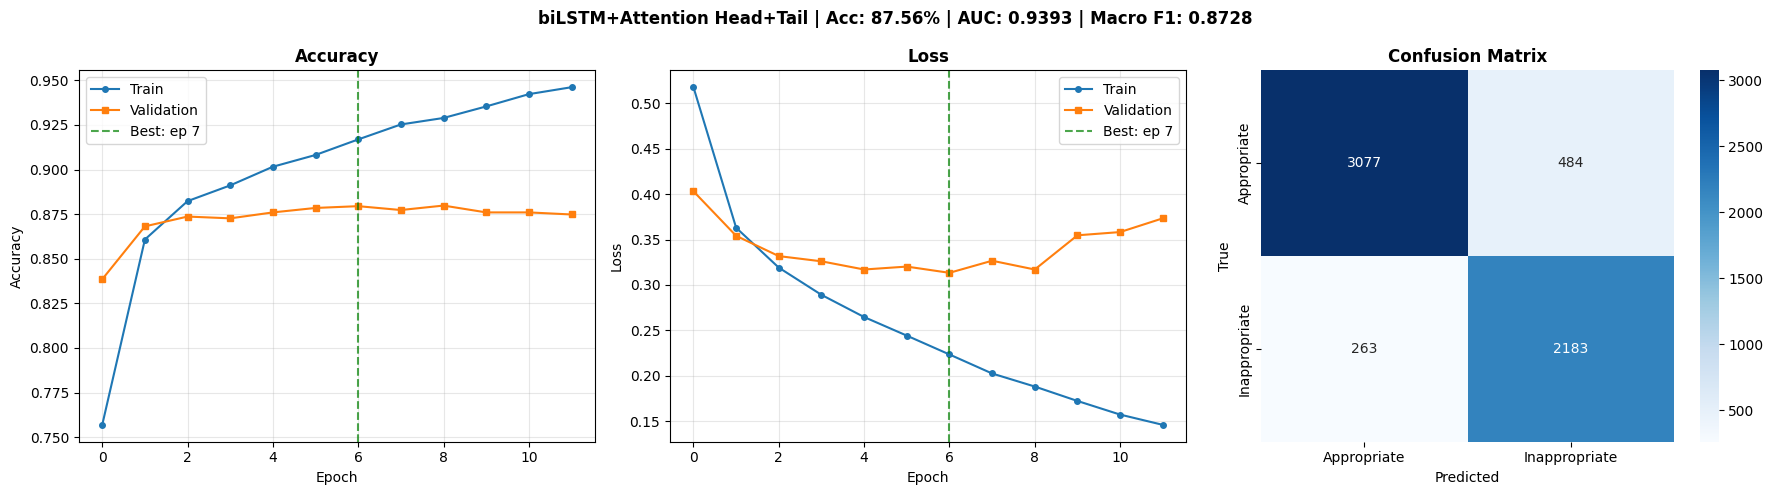

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history.history['accuracy'],     label='Train', marker='o', ms=4, linewidth=1.5)
axes[0].plot(history.history['val_accuracy'], label='Validation',  marker='s', ms=4, linewidth=1.5)
axes[0].axvline(best_epoch - 1, color='green', linestyle='--', alpha=0.7, label=f'Best: ep {best_epoch}')
axes[0].set_title('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'],     label='Train', marker='o', ms=4, linewidth=1.5)
axes[1].plot(history.history['val_loss'], label='Validation',  marker='s', ms=4, linewidth=1.5)
axes[1].axvline(best_epoch - 1, color='green', linestyle='--', alpha=0.7, label=f'Best: ep {best_epoch}')
axes[1].set_title('Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Appropriate', 'Inappropriate'],
    yticklabels=['Appropriate', 'Inappropriate'],
    ax=axes[2]
)
axes[2].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')

plt.suptitle(
    f'biLSTM+Attention Head+Tail | Acc: {acc*100:.2f}% | AUC: {auc:.4f} | Macro F1: {macro_f1:.4f}',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('bilstm_attention_result.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Visualisasi Attention Weights

Ini bonus — kita bisa lihat **token mana yang paling diperhatikan** model saat membuat keputusan.
Berguna untuk interpretasi dan presentasi hasil.

In [10]:
# Buat model khusus untuk ekstrak attention weights
attention_model = Model(
    inputs=model.input,
    outputs=model.get_layer('attention').output
)

# Balik mapping id → kata
idx2word = {v: k for k, v in tokenizer.word_index.items()}

def get_attention_weights(model_att, sequence_padded):
    """Ambil attention weights untuk satu sampel."""
    # Kita butuh weights sebelum weighted sum — modifikasi AttentionLayer
    # Alternatif: buat model yang output alpha langsung
    pass

def visualize_attention(text_raw, tokenizer, model, max_len=512, top_n=20):
    """
    Visualisasi token dengan attention weight tertinggi.
    Menunjukkan kata mana yang paling 'diperhatikan' model.
    """
    # Buat model yang output attention weights (alpha)
    att_weight_model = Model(
        inputs=model.input,
        outputs=[
            model.output,
            model.get_layer('attention').output
        ]
    )

    cleaned = clean_text(text_raw)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = smart_truncate_head_tail(seq, max_len)

    # Prediksi
    prob = model.predict(padded, verbose=0)[0][0]
    label = 'Inappropriate' if prob > 0.5 else 'Appropriate'

    # Konversi token ids kembali ke kata
    tokens = [idx2word.get(i, '<PAD>') for i in padded[0] if i != 0]

    print(f'Prediksi: {label} (prob={prob:.4f})')
    print(f'Teks   : {text_raw[:150]}...')
    print()

# Contoh penggunaan — ambil 3 sampel dari test set
print('Contoh sampel dari test set:')
for i in range(3):
    prob_val = y_prob[i]
    true_label = 'Inappropriate' if y_test[i] == 1 else 'Appropriate'
    pred_label = 'Inappropriate' if y_pred[i] == 1 else 'Appropriate'
    print(f'[{i+1}] True: {true_label} | Pred: {pred_label} | Prob: {prob_val:.4f}')
    print(f'     Teks: {X_test_raw[i][:120]}...')
    print()

Contoh sampel dari test set:
[1] True: Appropriate | Pred: Appropriate | Prob: 0.0149
     Teks: we re back all new uploads in february march l nursery rhymes abc songs kids songs data tidak tersedia komentar tidak te...

[2] True: Appropriate | Pred: Appropriate | Prob: 0.1015
     Teks: kaboochi menari dengan bayi hiu musik untuk kompetisi dansa kaboochi menari dengan bayi hiu lagu untuk anak anak tk kart...

[3] True: Inappropriate | Pred: Inappropriate | Prob: 0.9646
     Teks: jamming on thanksgiving badanamu compilation l nursery rhymes kids songs children s songs english education kindergarten...



## 11. Confidence Check

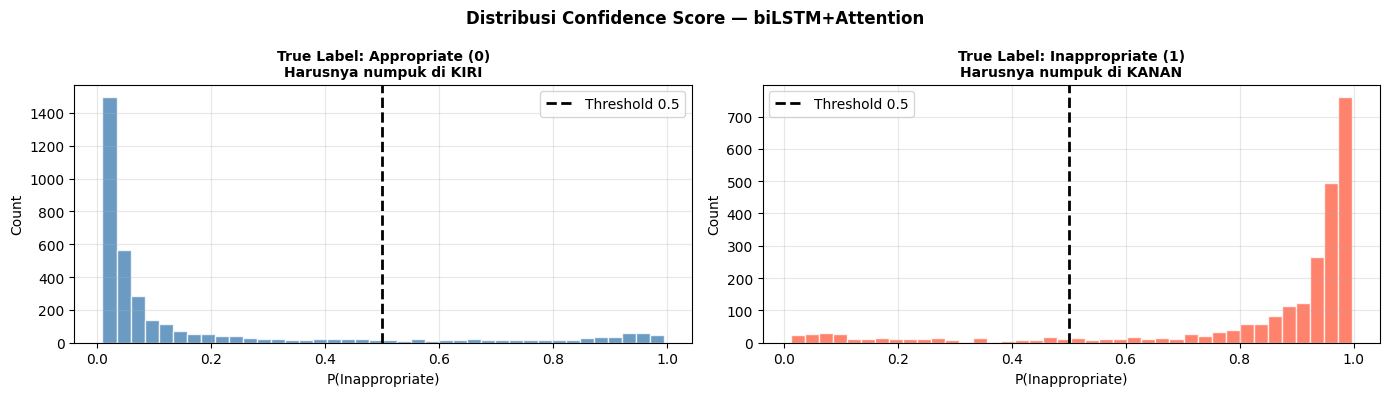

Rata-rata prob — Label 0: 0.1748
Rata-rata prob — Label 1: 0.8433
Separation gap          : 0.6685


In [11]:
results_df = pd.DataFrame({
    'text'      : X_test_raw,
    'true_label': y_test,
    'pred_label': y_pred,
    'prob'      : y_prob
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, label, color, title in [
    (axes[0], 0, 'steelblue', 'True Label: Appropriate (0)\nHarusnya numpuk di KIRI'),
    (axes[1], 1, 'tomato',    'True Label: Inappropriate (1)\nHarusnya numpuk di KANAN')
]:
    subset = results_df[results_df['true_label'] == label]['prob']
    ax.hist(subset, bins=40, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(0.5, color='black', linestyle='--', linewidth=2, label='Threshold 0.5')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('P(Inappropriate)'); ax.set_ylabel('Count')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle('Distribusi Confidence Score — biLSTM+Attention', fontweight='bold')
plt.tight_layout()
plt.savefig('bilstm_attention_confidence.png', dpi=150, bbox_inches='tight')
plt.show()

mean_0 = results_df[results_df['true_label']==0]['prob'].mean()
mean_1 = results_df[results_df['true_label']==1]['prob'].mean()
print(f'Rata-rata prob — Label 0: {mean_0:.4f}')
print(f'Rata-rata prob — Label 1: {mean_1:.4f}')
print(f'Separation gap          : {mean_1 - mean_0:.4f}')

## 12. Save Model

In [12]:
model.save('bilstm_attention_content_moderation.h5')
print('Model tersimpan: bilstm_attention_content_moderation.h5')

Model tersimpan: bilstm_attention_content_moderation.h5
